# Entrenamiento de YOLO (clasificación) — 5 clases de residuos

Este notebook entrena un clasificador de residuos con **YOLO11-cls** (Ultralytics) mediante *Transfer Learning*. Mantiene el mismo dataset, tamaño de imagen, batch y esquema de dos fases de los otros modelos, adaptando los parámetros que son propios de YOLO.

**Clases que aprende el modelo (5):** `aluminio`, `carton`, `otros`, `plastico`, `vidrio`.

> 🎯 **¿Por qué la variante `-cls` (clasificación) y no detección?** El dataset está organizado en una carpeta por clase y solo tiene una etiqueta por imagen (sin cajas delimitadoras). Eso es un problema de **clasificación**, igual que con EfficientNetB0. La detección necesitaría anotar cada imagen con *bounding boxes*.

**Flujo:** preparación del dataset, entrenamiento en dos fases, guardado del modelo nativo, exportación LiteRT/TFLite y gráfica de curvas; el notebook de evaluación calcula accuracy, loss, matriz de confusión, reporte, errores por imagen y accuracy por clase.

**Archivos que genera:**
* `models/YOLO/modelo_residuos_YOLO_v1.pt` — formato nativo PyTorch/Ultralytics, equivalente funcional al `.keras` de los modelos Keras.
* `models/YOLO/modelo_residuos_YOLO_v1.tflite` — versión LiteRT para inferencia en dispositivos compatibles.
* `reports/figures/curvas_entrenamiento_YOLO.png`
* `models/YOLO/runs/fase1/` y `models/YOLO/runs/fase2/` — checkpoints, historial CSV y gráficas de Ultralytics.

> **Formato:** YOLO está implementado en PyTorch; Ultralytics no exporta un archivo Keras `.keras`. No se debe renombrar `.pt` como `.keras`: el `.pt` es el modelo entrenable y recargable original de YOLO.

> 📁 Este notebook vive en `notebooks/YOLO/`; las rutas `Path("../..")` apuntan a la raíz del proyecto cuando el kernel trabaja desde esa carpeta.

> Ejecuta todas las celdas en orden usando el kernel **Python 3.12 (EntrenamientoIA YOLO)**.

### Instalación e importación de librerías

Este notebook usa el entorno separado **Python 3.12 (EntrenamientoIA YOLO)**, con PyTorch + CUDA, Ultralytics, pandas y matplotlib. Selecciona ese kernel antes de ejecutar las celdas. Mantenerlo separado evita conflictos entre PyTorch y TensorFlow/Keras.

Si necesitas preparar el entorno desde cero en Linux con una GPU NVIDIA compatible con CUDA 12.8, crea/activa `.venv-yolo` y ejecuta `pip install -r requirements-yolo.txt` desde la raíz del proyecto. Para otro controlador o plataforma, ajusta las versiones de PyTorch usando su selector oficial antes de instalar el resto de paquetes.

* **`ultralytics.YOLO`:** carga, entrena y exporta los modelos YOLO.
* **`torch`:** motor de Deep Learning de YOLO y comprobación de CUDA.
* **`pandas` y `matplotlib`:** leer el historial de entrenamiento (`results.csv`) y graficarlo.
* **`seaborn` y `scikit-learn`:** evaluación y visualización en el notebook de evaluación.
* **`shutil` y `pathlib.Path`:** copiar archivos y manejar rutas multiplataforma.

La exportación LiteRT puede instalar dependencias auxiliares específicas de Ultralytics en este entorno separado.

In [1]:
import shutil
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

### Comprobación de GPU

Verifica si PyTorch ve una **GPU NVIDIA**. Sin GPU el entrenamiento funciona, pero es mucho más lento.

La variable `DEVICE` se usa después en todas las llamadas de Ultralytics: `0` = primera GPU, `"cpu"` = procesador.

In [2]:
gpu_ok = torch.cuda.is_available()
print(f"¿PyTorch detecta la GPU?: {gpu_ok}")
if gpu_ok:
    print(f"Detalles del dispositivo: {torch.cuda.get_device_name(0)}")

DEVICE = 0 if gpu_ok else "cpu"

¿PyTorch detecta la GPU?: True
Detalles del dispositivo: NVIDIA GeForce RTX 4050 Laptop GPU


### Configuración de rutas y verificación del dataset

Igual que en el notebook de EfficientNetB0, usamos rutas **relativas** a la raíz del proyecto y **el mismo dataset**: `data/raw/waste_classification/` con las carpetas `train/` y `test/`, cada una con una subcarpeta por clase.

**Ultralytics y la carpeta `test/`:** para clasificación, Ultralytics busca `train/` y una carpeta de validación llamada `val/` **o** `test/`. Como aquí solo existe `test/`, la usa como validación automáticamente (igual que hacía el notebook de Keras), así que **no hay que mover ni copiar imágenes**.

**Verificación:** además de comprobar que existen las carpetas, se confirma que `train/` y `test/` tienen **las mismas clases** y se cuenta cuántas imágenes hay en cada una.

In [3]:
# Definir rutas relativas a partir del directorio base
BASE_DIR = Path("../..")
DATA_RAW_DIR = BASE_DIR / "data" / "raw"
DATASET_DIR = DATA_RAW_DIR / "waste_classification"
MODELS_DIR = BASE_DIR / "models" / "YOLO"
RUNS_DIR = MODELS_DIR / "runs"
FIGURES_DIR = BASE_DIR / "reports" / "figures"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Crear carpetas de salida si no existen
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def contar_imagenes(carpeta):
    """Devuelve {clase: número de imágenes} para una carpeta con subcarpetas por clase."""
    return {
        c.name: sum(1 for f in c.rglob("*") if f.suffix.lower() in IMG_EXT)
        for c in sorted(carpeta.iterdir()) if c.is_dir()
    }


# Verificación estricta de la existencia de los datos
if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró la estructura esperada en {DATASET_DIR}. "
        "Coloca las carpetas 'train' y 'test' manualmente ahí."
    )

train_counts = contar_imagenes(TRAIN_DIR)
test_counts = contar_imagenes(TEST_DIR)

assert set(train_counts) == set(test_counts), (
    f"train y test no tienen las mismas clases:\n train={sorted(train_counts)}\n test={sorted(test_counts)}"
)

print("✅ Directorios de datos detectados correctamente.")
print(f"   Clases ({len(train_counts)}): {list(train_counts)}")
print(f"   Imágenes de entrenamiento: {sum(train_counts.values())}  -> {train_counts}")
print(f"   Imágenes de validación   : {sum(test_counts.values())}  -> {test_counts}")

✅ Directorios de datos detectados correctamente.
   Clases (5): ['aluminio', 'carton', 'otros', 'plastico', 'vidrio']
   Imágenes de entrenamiento: 18123  -> {'aluminio': 3549, 'carton': 2916, 'otros': 4651, 'plastico': 5068, 'vidrio': 1939}
   Imágenes de validación   : 4535  -> {'aluminio': 888, 'carton': 730, 'otros': 1164, 'plastico': 1268, 'vidrio': 485}


### Configuración del entrenamiento

Todos los valores que deben coincidir con el notebook de EfficientNetB0 están reunidos en una sola celda para que sea fácil auditarlos o cambiarlos.

**Valores iguales a los de EfficientNetB0:**
* **`IMG_SIZE = 224`:** mismo tamaño de entrada.
* **`BATCH_SIZE = 32`**.
* **`EPOCHS_FASE1 = 15`** y **`EPOCHS_FASE2 = 20`**.
* **`LR_FASE1 = 1e-3`** y **`LR_FASE2 = 1e-5`**.
* **Optimizador Adam** (con `weight_decay = 0` y `momentum = 0.9`, que equivale al `beta_1` por defecto de Adam en Keras; por defecto Ultralytics usa valores distintos).
* **Learning rate constante** (`lrf = 1.0`) y **sin *warmup*** (`warmup_epochs = 0`): Keras usaba el learning rate fijo durante toda la fase, mientras que Ultralytics por defecto lo reduce poco a poco y hace un calentamiento al inicio.

**El modelo base: `MODEL_BASE`**
* Por defecto es **`yolo11s-cls.pt`** (~5.5 M de parámetros), el tamaño más cercano a EfficientNetB0 (~5.3 M) y MobileNetV3-Large (~5.4 M).
* Otras opciones de la familia: `yolo11n-cls.pt` (~1.6 M, el más ligero, ideal para la Raspberry Pi) y `yolo11m-cls.pt` (~10 M).
* Los pesos preentrenados en ImageNet se descargan solos la primera vez (requiere internet).

**Congelamiento por fases (`freeze`):** en Ultralytics `freeze=N` congela las **primeras N capas** del modelo. En YOLO11-cls el backbone son las capas 0–9 y la cabeza de clasificación (`Classify`) es la capa 10:
* **Fase 1 → `FREEZE_FASE1 = 10`:** congela todo el backbone; solo se entrena la cabeza.
* **Fase 2 → `FREEZE_FASE2 = 7`:** congela las capas 0–6 (el ~70 % inferior) y entrena las 4 capas superiores (el ~30 %), análogo al «70/30» de EfficientNetB0.

> ℹ️ El modelo tiene solo 11 capas «grandes» (bloques), no 238 como EfficientNetB0, así que el 70/30 no puede ser exacto: es la aproximación más cercana. La celda de la Fase 1 imprime qué capas quedan congeladas, para que lo verifiques.

In [4]:
# --- Modelo base ---
MODEL_BASE = "yolo11s-cls.pt"   # alternativas: "yolo11n-cls.pt", "yolo11m-cls.pt"

# --- Valores idénticos a entrenamiento_EfficientNetB0.ipynb ---
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_FASE1 = 15
EPOCHS_FASE2 = 20
LR_FASE1 = 1e-3
LR_FASE2 = 1e-5

# --- Congelamiento (número de capas iniciales que se congelan) ---
FREEZE_FASE1 = 10   # backbone completo (capas 0-9): solo se entrena la cabeza
FREEZE_FASE2 = 7    # capas 0-6 congeladas (~70 %), capas 7-10 entrenables (~30 %)

SEED = 0
WORKERS = 8         # hilos para cargar imágenes; bájalo si te quedas sin RAM

# Argumentos comunes a las dos fases (equivalen a un Adam "plano" de Keras)
COMMON_ARGS = dict(
    data=str(DATASET_DIR.resolve()),
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    optimizer="Adam",
    weight_decay=0.0,
    momentum=0.9,
    lrf=1.0,             # learning rate constante durante toda la fase
    warmup_epochs=0,     # sin calentamiento
    patience=0,          # sin parada anticipada (se entrenan todas las épocas)
    device=DEVICE,
    workers=WORKERS,
    seed=SEED,
    project=str(RUNS_DIR.resolve()),
    exist_ok=True,       # permite volver a ejecutar sin crear carpetas fase1-2, fase1-3...
    plots=True,
    verbose=True,
)
print("Configuración lista.")

Configuración lista.


### Fase 1 — Entrenar solo la cabeza (backbone congelado)

Aquí ocurre lo mismo que en la Fase 1 del notebook de Keras: se carga el modelo preentrenado en ImageNet, se **congela el backbone** y se entrena únicamente la capa final de clasificación para que aprenda las 5 clases.

**¿Qué hace Ultralytics por su cuenta?**
* Detecta que el dataset tiene 5 clases y **reemplaza la última capa** del modelo (que era de 1000 clases de ImageNet) por una de 5.
* Lee las carpetas `train/` y `test/` (esta última como validación) y evalúa al final de cada época.
* Aplica su propio *data augmentation* para clasificación (recortes aleatorios con zoom, volteo horizontal, cambios de color y *RandAugment*).

> ⚠️ **Diferencia con EfficientNetB0:** el aumento de datos **no es idéntico**. En Keras se usaba rotación de hasta 30°, desplazamientos del 20 % y zoom del 30 %; el pipeline de clasificación de Ultralytics no ofrece rotación ni desplazamiento (usa recortes aleatorios y RandAugment). Es una diferencia inevitable de la herramienta, y conviene mencionarla en el reporte comparativo.

**Cómo leer la salida:** por época verás `loss` (error en entrenamiento) y `top1_acc` / `top5_acc` (accuracy en validación). Con 5 clases `top5_acc` siempre vale 1.0 porque *cualquier* clase está dentro de las 5 mejores; **el número que importa es `top1_acc`**, equivalente al `val_accuracy` de Keras.

In [5]:
print(f"Cargando modelo base {MODEL_BASE} ...")
model = YOLO(MODEL_BASE)

print("\nIniciando entrenamiento (Fase 1 - Cabeza)...")
print("   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).")

results_f1 = model.train(
    **COMMON_ARGS,
    name="fase1",
    epochs=EPOCHS_FASE1,
    lr0=LR_FASE1,
    freeze=FREEZE_FASE1,
)

print("¡Entrenamiento fase 1 completado!")

Cargando modelo base yolo11s-cls.pt ...

Iniciando entrenamiento (Fase 1 - Cabeza)...
   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).
Ultralytics 8.4.178 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5800MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/cachyisus/Proyectos/EntrenamientoIA/data/raw/waste_classification, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1

### Revisión de la Fase 1 (qué se congeló y qué se logró)

Antes de pasar al fine-tuning verificamos dos cosas:

1.  **Cuántos parámetros son entrenables.** En la Fase 1 deben ser pocos (solo la cabeza). Ultralytics también imprime en el log del entrenamiento líneas del tipo `freezing model.0.conv.weight`, con la lista de capas congeladas.
2.  **El accuracy de validación al terminar la fase** (`top1`), para compararlo con el 0.9614 de EfficientNetB0 en la misma etapa.

`last.pt` es el modelo de la **última época**. Es el que se usa para arrancar la Fase 2 (igual que Keras, que seguía desde el estado final, no desde el «mejor»).

In [6]:
LAST_F1 = RUNS_DIR / "fase1" / "weights" / "last.pt"
assert LAST_F1.exists(), f"No se encontró {LAST_F1}. ¿Terminó bien la Fase 1?"

hist1 = pd.read_csv(RUNS_DIR / "fase1" / "results.csv")
hist1.columns = hist1.columns.str.strip()
top1_f1 = hist1["metrics/accuracy_top1"].iloc[-1]
print(f"Accuracy de validación (top1) al final de la Fase 1: {top1_f1:.4f}")
print(f"   (referencia EfficientNetB0 al final de su Fase 1: 0.9614)")

n_total = sum(p.numel() for p in model.model.parameters())
n_train = sum(p.numel() for p in model.model.parameters() if p.requires_grad)
print(f"\nParámetros totales    : {n_total:,}")
print(f"Parámetros entrenables: {n_train:,} (puede aparecer sin congelar porque Ultralytics restaura el estado tras entrenar)")

Accuracy de validación (top1) al final de la Fase 1: 0.9687
   (referencia EfficientNetB0 al final de su Fase 1: 0.9614)

Parámetros totales    : 5,449,413
Parámetros entrenables: 0 (puede aparecer sin congelar porque Ultralytics restaura el estado tras entrenar)


### Fine-tuning (Fase 2: afinamiento de precisión)

Se parte del modelo que terminó la Fase 1 (`last.pt`) y se **descongela parte del backbone** para que se adapte a las imágenes de residuos:

* **`freeze = 7`:** quedan congeladas las capas 0–6 (~70 % inferior, bordes y texturas simples) y se entrenan las capas 7–10 (~30 % superior, formas complejas + la cabeza).
* **Learning rate `1e-5`** (100 veces menor que en la Fase 1): son «micro-ajustes» para no destruir lo aprendido (*catastrophic forgetting*).
* **20 épocas más**, con los mismos datos y las mismas condiciones.

> ℹ️ A diferencia de Keras, aquí **no hace falta «recompilar»**: al llamar a `train()` otra vez con otro `freeze` y otro `lr0`, Ultralytics reconstruye el optimizador desde cero con la nueva configuración.

In [7]:
print("Iniciando configuración de Fine-Tuning...")
print(f"   Se parte de: {LAST_F1}")

model_ft = YOLO(str(LAST_F1))

print("\nIniciando Fase 2 de Entrenamiento (Fine-Tuning)...")
print("   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.")

results_f2 = model_ft.train(
    **COMMON_ARGS,
    name="fase2",
    epochs=EPOCHS_FASE2,
    lr0=LR_FASE2,
    freeze=FREEZE_FASE2,
)

print("¡Entrenamiento completo finalizado!")

Iniciando configuración de Fine-Tuning...
   Se parte de: ../../models/YOLO/runs/fase1/weights/last.pt

Iniciando Fase 2 de Entrenamiento (Fine-Tuning)...
   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.
Ultralytics 8.4.178 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5800MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/cachyisus/Proyectos/EntrenamientoIA/data/raw/waste_classification, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

### Guardado del modelo (la «copia maestra»)

Se guarda el modelo **de la última época de la Fase 2** (`last.pt`), igual que el notebook de Keras guardaba el modelo final.

* **Formato `.pt`:** es el formato nativo de PyTorch/Ultralytics. Contiene la arquitectura y los pesos, y es lo que se carga con `YOLO("archivo.pt")`.
* **Ruta de salida:** `models/YOLO/modelo_residuos_YOLO_v1.pt`.

> 💡 Ultralytics también deja `best.pt` (la mejor época según `top1`) en `runs/fase2/weights/`. Si prefieres evaluar ese, cambia `last.pt` por `best.pt` aquí abajo; para comparar «en igualdad de condiciones» con EfficientNetB0 se usa el modelo final.

In [8]:
LAST_F2 = RUNS_DIR / "fase2" / "weights" / "last.pt"
assert LAST_F2.exists(), f"No se encontró {LAST_F2}. ¿Terminó bien la Fase 2?"

model_save_path = MODELS_DIR / "modelo_residuos_YOLO_v1.pt"

print(f"Guardando modelo maestro en: {model_save_path} ...")
shutil.copy2(LAST_F2, model_save_path)

print("¡Éxito! El archivo está listo.")
print(f"   Ruta absoluta: {model_save_path.resolve()}")

Guardando modelo maestro en: ../../models/YOLO/modelo_residuos_YOLO_v1.pt ...
¡Éxito! El archivo está listo.
   Ruta absoluta: /home/cachyisus/Proyectos/EntrenamientoIA/models/YOLO/modelo_residuos_YOLO_v1.pt


### Exportación a LiteRT / TensorFlow Lite (Edge AI)

El checkpoint nativo `.pt` se conserva para continuar entrenando e inferir con Ultralytics. Además se exporta un `.tflite` para despliegue mediante LiteRT/TFLite.

**Cuantización seleccionada:** `w8a32` (INT8 dinámico en los pesos y activaciones FP32). No requiere conjunto de calibración y es compatible con el flujo de exportación LiteRT de Ultralytics 8.4. El modo FP16 heredado no se usa: esta versión de LiteRT no genera un artefacto FP16 separado para este flujo.

La exportación produce `models/YOLO/modelo_residuos_YOLO_v1.tflite`. Puede requerir dependencias auxiliares, que Ultralytics instala en el entorno YOLO aislado. Si la conversión falla, el checkpoint `.pt` permanece guardado y el error se muestra sin confundirlo con una exportación exitosa.

> YOLO no genera `.keras` porque ese es un formato propio de Keras. El equivalente nativo de YOLO es `.pt`; el `.tflite` es el formato de inferencia ligero.

In [9]:
TFLITE_MODE = "w8a32"  # cuantización LiteRT dinámica: pesos INT8, activaciones FP32

print("Iniciando exportación a LiteRT / TFLite...")
tflite_save_path = MODELS_DIR / "modelo_residuos_YOLO_v1.tflite"

try:
    export_model = YOLO(str(model_save_path))
    exported = Path(
        export_model.export(
            format="litert",
            imgsz=IMG_SIZE,
            device="cpu",
            quantize=TFLITE_MODE,
        )
    )
    if not exported.is_file():
        raise FileNotFoundError(f"Ultralytics no devolvió un archivo TFLite: {exported}")

    if exported.resolve() != tflite_save_path.resolve():
        shutil.copy2(exported, tflite_save_path)

    pt_size = model_save_path.stat().st_size / (1024 * 1024)
    tflite_size = tflite_save_path.stat().st_size / (1024 * 1024)
    print(f"Modelo LiteRT/TFLite guardado en: {tflite_save_path.resolve()}")
    print(f"\nReporte de optimización ({TFLITE_MODE}):")
    print(f"   Tamaño original (.pt)       : {pt_size:.2f} MB")
    print(f"   Tamaño optimizado (.tflite) : {tflite_size:.2f} MB")
    print(f"   Reducción de tamaño         : {(1 - tflite_size / pt_size) * 100:.2f}%")

except Exception as e:
    print(f"⚠️ No se pudo exportar a TFLite: {type(e).__name__}: {e}")
    print("El checkpoint .pt sí quedó guardado; revisa las dependencias de exportación de Ultralytics y reintenta esta celda.")

Iniciando exportación a LiteRT / TFLite...
Ultralytics 8.4.178 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (13th Gen Intel Core i7-13700H)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s-cls summary (fused): 47 layers, 5,440,533 parameters, 0 gradients, 1.5 GFLOPs

PyTorch: starting from '../../models/YOLO/modelo_residuos_YOLO_v1.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 5) (10.5 MB)
requirements: Ultralytics requirements ['litert-torch>=0.9.0', 'ai-edge-litert>=2.1.4'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo
Resolved 87 packages in 1.40s
 Downloaded xdsl
 Downloaded sentencepiece
 Downloaded tokenizers
 Downloaded jax
 Downloaded torchao
 Downloaded hf-xet
 Downloaded transformers
 Downloaded ai-edge-litert
 Downloaded jaxlib
 Downloaded litert-converter
Prepared 47 packages in 6.

I0000 00:00:1792211601.122246  152071 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Failed to load /home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
Failed to load /home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so
/home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: inva


LiteRT: starting export with litert_torch 0.9.4...


/home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(00:00) [START] LiteRT-Torch Convert

...

(00:00) [START] Write Model to ../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite

(00:00) [ DONE] Write Model to ../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite (+00:00)

LiteRT: applying dynamic INT8 quantization (int8 weights + FP32 activations)...


Applying Transformations to tensors:: 100%|██████████| 272/272 [00:00<00:00, 420202.83it/s]


Model name: ../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite
Original model size: 20.83 MiB
Quantized model size: 5.39 MiB
Quantization Ratio: 0.26 (3.9x smaller)
Total time: 35.29 ms
LiteRT: export success ✅ 14.0s, saved as '../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite' (5.4 MB)

Export complete (14.2s)
Results saved to /home/cachyisus/Proyectos/EntrenamientoIA/models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite
Predict:         yolo predict task=classify model=../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite imgsz=224 
Validate:        yolo val task=classify model=../../models/YOLO/modelo_residuos_YOLO_v1_w8a32.tflite imgsz=224 data=/home/cachyisus/Proyectos/EntrenamientoIA/data/raw/waste_classification 
Visualize:       https://netron.app
Modelo LiteRT/TFLite guardado en: /home/cachyisus/Proyectos/EntrenamientoIA/models/YOLO/modelo_residuos_YOLO_v1.tflite

Reporte de optimización (w8a32):
   Tamaño original (.pt)       : 10.52 MB
   Tamaño optimizado (.tflite) : 5

### Curvas de entrenamiento (accuracy y loss)

Se unen los historiales de las **dos fases** (`runs/fase1/results.csv` + `runs/fase2/results.csv`) y se grafican en una sola figura, igual que en el notebook de EfficientNetB0.

* **Izquierda — Accuracy:** `top1` de validación época por época.
* **Derecha — Loss:** error en entrenamiento y en validación.
* **Línea roja punteada:** marca la época 15, donde termina la Fase 1 y empieza el fine-tuning.

> ℹ️ **Diferencia con el notebook de Keras:** Ultralytics, en clasificación, **no registra el accuracy de entrenamiento**, solo el *loss* de entrenamiento. Por eso aquí la gráfica de accuracy muestra únicamente la curva de validación.

La figura se guarda en `reports/figures/curvas_entrenamiento_YOLO.png`.

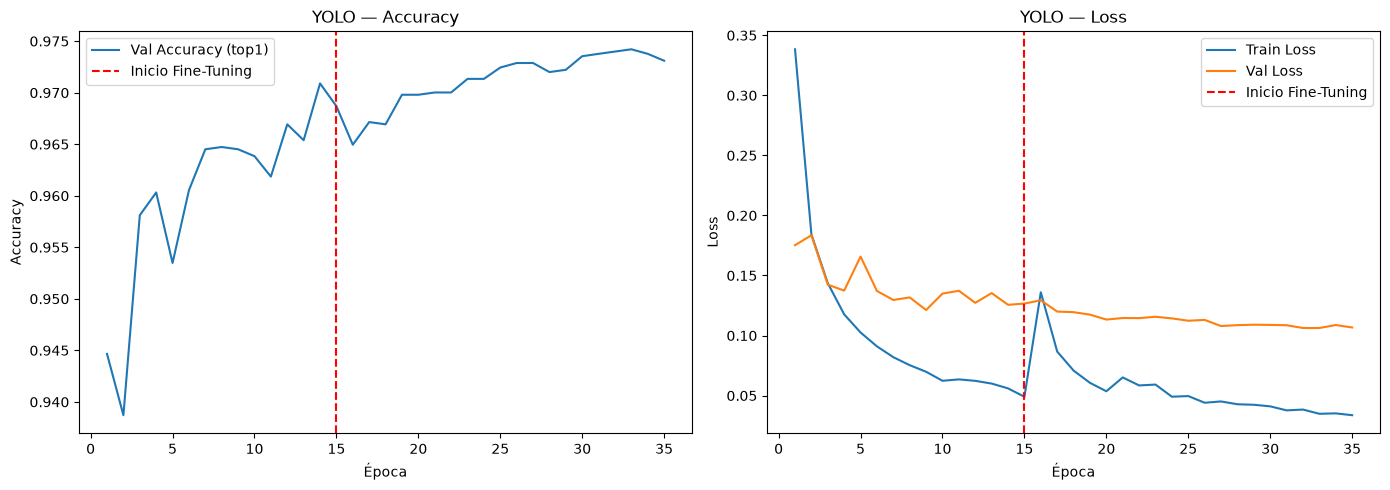

Gráfica guardada.

Val accuracy (top1) final: 0.9731


In [10]:
def leer_historial(fase):
    df = pd.read_csv(RUNS_DIR / fase / "results.csv")
    df.columns = df.columns.str.strip()
    return df


h1 = leer_historial("fase1")
h2 = leer_historial("fase2")
hist = pd.concat([h1, h2], ignore_index=True)
hist["epoca"] = range(1, len(hist) + 1)

fine_tune_start = len(h1)   # Época donde empieza el fine-tuning (15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(hist["epoca"], hist["metrics/accuracy_top1"], label="Val Accuracy (top1)")
ax1.axvline(x=fine_tune_start, color="r", linestyle="--", label="Inicio Fine-Tuning")
ax1.set_title("YOLO — Accuracy")
ax1.set_xlabel("Época")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(hist["epoca"], hist["train/loss"], label="Train Loss")
ax2.plot(hist["epoca"], hist["val/loss"], label="Val Loss")
ax2.axvline(x=fine_tune_start, color="r", linestyle="--", label="Inicio Fine-Tuning")
ax2.set_title("YOLO — Loss")
ax2.set_xlabel("Época")
ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "curvas_entrenamiento_YOLO.png", dpi=150)
plt.show()
print("Gráfica guardada.")
print(f"\nVal accuracy (top1) final: {hist['metrics/accuracy_top1'].iloc[-1]:.4f}")